# Hexapod actuator stick-slip during exposures — slips and chatter: rates and effects

**Question.** Two different uncommanded hexapod-actuator behaviours were seen during LSSTCam exposures with the
hexapod demand constant:

* **Slip** — MC_O_20261107_000096, **M2 hexapod actuator 3**: four isolated transients, measured length −1.8 µm then
  +1.6 µm, motor current ±2 A, ≈0.3 s each.
* **Chatter** — MC_O_20261108_000548, **M2 hexapod actuator 6**: a sustained ±2.5 µm saw-tooth at ≈2 Hz for the whole
  exposure, dragging the hexapod's y position by ≈±1.3 µm.

How often does each happen, on which actuators of which hexapod, under what conditions, and do they affect the images?

**Data.**
* EFD `MTHexapod.actuators` (`positionError0–5`, `calibrated0–5`) and `MTHexapod.application` (`demand0–5`,
  `position0–5`) for both hexapods (salIndex 1 = camera, 2 = M2), reduced server-side to **1-s max / min / mean** over
  every night with LSSTCam science exposures since 2025-04 (a 1-s max/min captures sub-second transients without
  pulling 20 Hz data).
* Full-rate windows (`positionError`, `calibrated`, `motorCurrent`, `position`, `demand`) for example exposures.
* ConsDB `cdb_lsstcam.exposure` (science, `exp_time ≥ 10 s`) and `visit1_quicklook` (PSF moments, guider metrics).

All caches are written by [build_hexapod_slip.py](build_hexapod_slip.py) into `data/` (gitignored).

**Per-exposure metrics** (window [obs_start + 1.5 s, obs_end − 0.3 s], ConsDB TAI → UTC, whole 1-s bins only), per
actuator: **peak** |bin max/min − exposure median| of the following error; **slip events** = separate runs of bins with
deviation > 0.8 µm; **chatter fraction** = fraction of bins whose in-bin peak-to-peak exceeds 1 µm; median actuator
length. An actuator-exposure is classed **chatter** if the chatter fraction ≥ 0.3, otherwise **slip** if it has ≥ 1
slip event. Excluded: exposures in which the hexapod *demand* changed (commanded move), and exposures in which the
hexapod was still travelling (x/y/z excursion > 10 µm — a move that had not finished, or a demand step that fell exactly
on a 1-s bin boundary); the latter are listed in §2.

Companion: [TMA_AzEncoderHeadLoss_Impulse.ipynb](TMA_AzEncoderHeadLoss_Impulse.ipynb) (exposure 69 of 20261107).

## Key findings (2026-11-09)

Scan of **103,713 LSSTCam science exposures on 270 nights (2025-04-12 → 2026-11-08)**. After excluding commanded or
unfinished hexapod motion, the usable sample is 84,935 exposures (670 h) for the M2 hexapod and 80,071 (631 h) for the
camera hexapod. Rates per hour of exposure time.

1. **Slips are a real single-actuator stick-slip, almost all on the M2 hexapod.**

   | | slips / exp-hour | exposures with a slip | slip nights | single-actuator |
   |---|---|---|---|---|
   | M2 act 2 | **3.0** | 1.8 % | 179 | 95 % |
   | M2 act 6 | **2.4** | 1.3 % | 141 | 97 % |
   | M2 act 3 | **1.8** | 0.8 % | 93 | 95 % |
   | M2 act 1 | 0.8 | 0.6 % | 136 | 80 % |
   | M2 act 5 / act 4 | 0.19 / 0.004 | ≤ 0.15 % | | |
   | camera act 6 | 0.75 | 0.5 % | 127 | 92 % |
   | camera act 1–5 | 0.03–0.05 | ≤ 0.04 % | | ≤ 29 % — mostly common-mode |

   On camera actuators 1–5 the events are mostly simultaneous on several actuators and on both hexapods. They are
   external disturbances (mount kicks), not actuator slips.
2. **Chatter (sustained stick-slip limit cycle) is dominated by M2 actuator 3.** It chattered in **2.8 % of all
   exposures (2.1 % of exposure time) on 86 nights**. M2 actuator 6, the 20261108/548 case, chattered in 0.09 % on
   30 nights, and camera actuator 6 in 0.03 %.
3. **Actuator 3 chatter depends strongly on pointing and temperature.** It is essentially absent above 55° elevation.
   Below 55° it grows with colder air: at el 35–45° it affects **51 % of exposures at ≤ 5 °C**, 24 % at 5–9 °C and 3 %
   above 13 °C. Both trends fit stick-slip at low axial load, with friction rising in the cold.
4. **It is getting worse.** At el < 45° the chatter fraction went from 0 % (2025-04 → 07) to 10–13 % (Dec–Jan),
   dropped to 0.3–1.7 % in Feb–Mar 2026, and has been **24–32 % every month since 2026-05**, including 30 % in
   November 2026. Median temperatures in those months are similar (~8–12 °C), so the change is in the actuator, not
   in the season.
5. **Effect on M2 position is ~1 µm.** 95th-percentile excursions: slips 1.1 µm (x, y, z) and 0.16″ tilt; chatter
   0.9 µm in y; clean exposures 0.05–0.10 µm.
6. **No meaningful image impact.** Against clean neighbouring exposures, PSF FWHM rises by **≤ 0.007″** in every class
   (M2 chatter +0.007″, 68 % interval +0.004 … +0.009″). PSF ellipticity and guider rms change by ≤ 0.002. This is a
   mechanical-health issue, not an image-quality one, at today's amplitudes.
7. **Side finding: 65 exposures started while a hexapod was still travelling** (up to 4.6 mm, constant in-window
   demand). Most were in 2025-04 → 06 and 2026-04; a few have PSF e ≈ 0.6.

## Setup

In [1]:
import pathlib
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
from IPython.display import display

warnings.filterwarnings("ignore")
pd.set_option("display.width", 200)
pd.set_option("display.max_columns", 40)

DATA = pathlib.Path("data")
EX_SLIP, EX_CHAT = 2026110700096, 2026110800548
HEXES = {"m2": "M2 hexapod", "cam": "camera hexapod"}
ACTS = range(1, 7)
THR = 0.8          # µm, slip threshold (§2)
CHAT = 0.3         # chatter: fraction of 1-s bins with in-bin p2p > 1 µm

C_M2, C_CAM, C_GRAY, C_FAULT, C_WARN = "#2a78d6", "#eb6834", "#8a8984", "#e34948", "#eda100"
C6 = ["#2a78d6", "#eb6834", "#1f9e89", "#9b59b6", "#eda100", "#5c5b57"]
plt.rcParams.update({
    "figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.color": "#e4e3df", "grid.linewidth": 0.6,
    "axes.edgecolor": "#8a8984", "axes.titlesize": 10, "axes.labelsize": 9,
    "xtick.labelsize": 8, "ytick.labelsize": 8, "legend.fontsize": 8, "lines.linewidth": 1.4,
    "axes.prop_cycle": plt.cycler(color=C6),
})

In [2]:
exl = pd.read_parquet(DATA / "hexslip_exposure_list.parquet")
per = pd.read_parquet(DATA / "hexslip_exposures.parquet")
ql = pd.read_parquet(DATA / "hexslip_quicklook.parquet").drop_duplicates("exposure_id")
X = exl.merge(per, on="exposure_id", how="inner").merge(ql, on="exposure_id", how="left")
X["date"] = pd.to_datetime(X.day_obs.astype(str))
X["dur_h"] = ((X.t1 - X.t0).dt.total_seconds() - 1.5 - 1.3) / 3600       # analysed time per exposure
X["psf_e"] = np.hypot(X.psf_ixx_median - X.psf_iyy_median, 2 * X.psf_ixy_median) / (X.psf_ixx_median + X.psf_iyy_median)
X["psf_fwhm"] = X.psf_sigma_median * 2.355 * 0.2
MOVING = 10.0      # µm — hexapod x/y/z excursion above which the hexapod was still travelling (not a slip)
for nm in HEXES:
    X[f"{nm}_moving"] = X[[f"{nm}_pos_{c}_peak" for c in "xyz"]].max(axis=1) > MOVING
    X[f"{nm}_ok"] = (X[f"{nm}_nbins"] >= 5) & (X[f"{nm}_demand_moved"] == False) & ~X[f"{nm}_moving"]  # noqa: E712
    for i in ACTS:
        X[f"{nm}_a{i}_chat"] = X[f"{nm}_a{i}_fp2p1"] >= CHAT
        X[f"{nm}_a{i}_slip"] = (X[f"{nm}_a{i}_n0p8"] > 0) & ~X[f"{nm}_a{i}_chat"]
    X[f"{nm}_any_chat"] = X[[f"{nm}_a{i}_chat" for i in ACTS]].any(axis=1)
    X[f"{nm}_any_slip"] = X[[f"{nm}_a{i}_slip" for i in ACTS]].any(axis=1)
    X[f"{nm}_maxpk"] = X[[f"{nm}_a{i}_peak" for i in ACTS]].max(axis=1)
print(f"science exposures scanned: {len(X):,} on {X.day_obs.nunique()} nights "
      f"({X.date.min():%Y-%m-%d} → {X.date.max():%Y-%m-%d}); "
      + "; ".join(f"{HEXES[nm]} usable {X[f'{nm}_ok'].sum():,}" for nm in HEXES))

science exposures scanned: 103,713 on 270 nights (2025-04-12 → 2026-11-08); M2 hexapod usable 84,909; camera hexapod usable 80,019


## 1. The two examples

Full-rate telemetry, shutter-open time shaded. In both cases the demand is constant; the hexapod compensation update only
comes ≈0.3 s after the shutter closes.

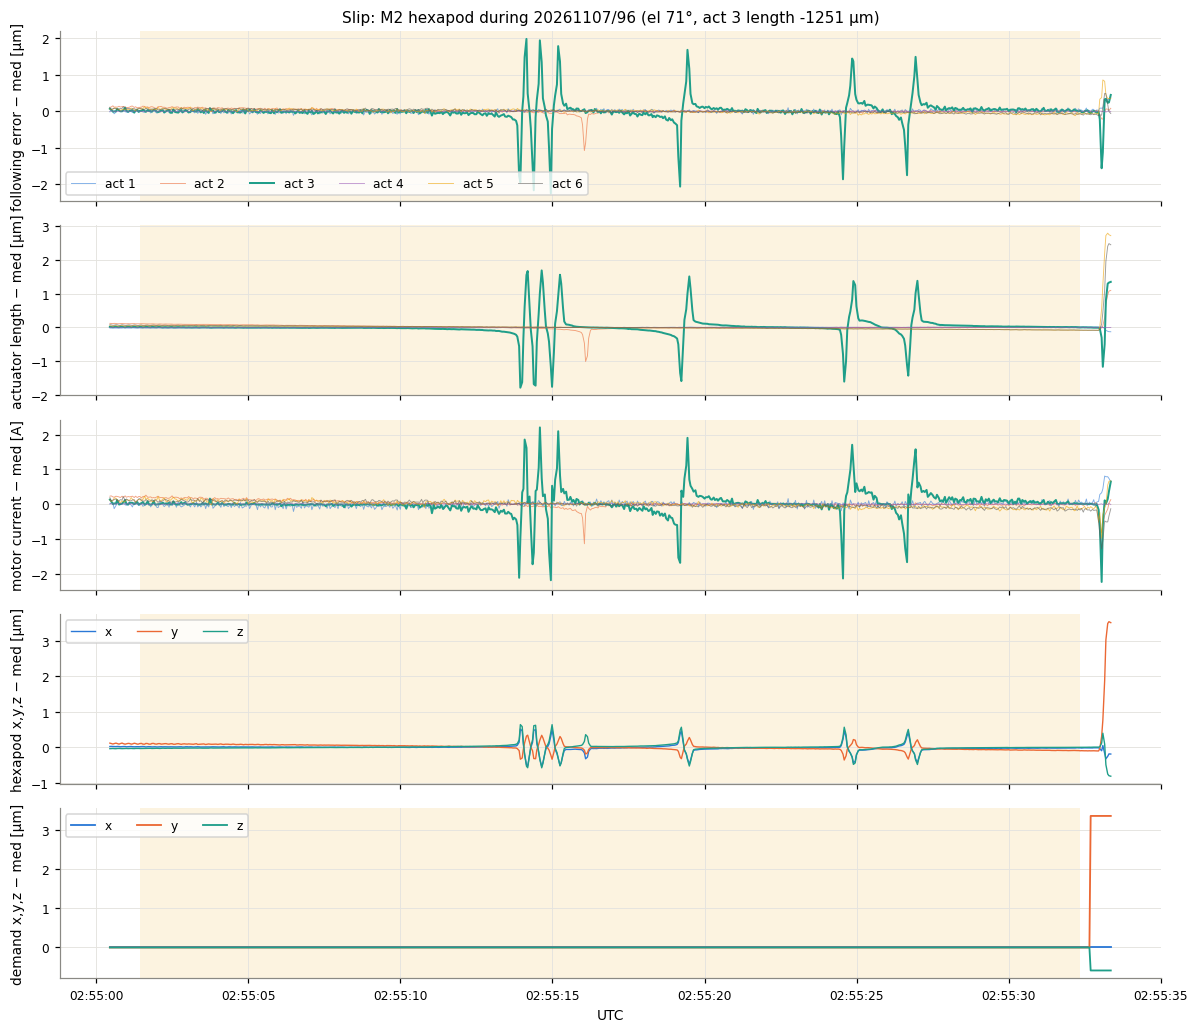

scan metrics act 3: peak 2.25 µm, slip runs 4, chatter fraction 0.21


In [3]:
def show_example(eid, act, title):
    ex = pd.read_parquet(DATA / f"hexslip_example_{eid}.parquet")
    e = X.set_index("exposure_id").loc[eid]
    z = ex[(ex.index > e.t0 - pd.Timedelta("1s")) & (ex.index < e.t1 + pd.Timedelta("1s"))]
    fig, ax = plt.subplots(5, 1, figsize=(11, 9.5), sharex=True)
    for i in range(6):
        for k, pfx in enumerate(["m2_act_positionError", "m2_act_calibrated", "m2_ele_motorCurrent"]):
            s = z[f"{pfx}{i}"].dropna()
            ax[k].plot(s.index, s - s.median(), lw=1.3 if i == act - 1 else 0.6, color=C6[i],
                       alpha=1 if i == act - 1 else 0.6, label=f"act {i + 1}")
    for i, lab in enumerate("xyz"):
        s = z[f"m2_app_position{i}"].dropna(); ax[3].plot(s.index, s - s.median(), lw=0.9, label=lab)
        s = z[f"m2_app_demand{i}"].dropna(); ax[4].plot(s.index, s - s.median(), lw=1.2, label=lab)
    ax[0].legend(ncol=6, loc="lower left"); ax[3].legend(ncol=3); ax[4].legend(ncol=3)
    for a, lab in zip(ax, ["following error − med [µm]", "actuator length − med [µm]", "motor current − med [A]",
                           "hexapod x,y,z − med [µm]", "demand x,y,z − med [µm]"]):
        a.set_ylabel(lab); a.axvspan(e.t0, e.t1, color=C_WARN, alpha=0.12, lw=0)
    ax[0].set_title(f"{title}: M2 hexapod during {eid // 100000}/{eid % 100000} "
                    f"(el {e.altitude:.0f}°, act {act} length {e[f'm2_a{act}_len']:.0f} µm)")
    ax[-1].xaxis.set_major_formatter(mdates.DateFormatter("%H:%M:%S")); ax[-1].set_xlabel("UTC")
    fig.align_ylabels(); plt.tight_layout(); plt.show()
    print(f"scan metrics act {act}: peak {e[f'm2_a{act}_peak']:.2f} µm, slip runs {int(e[f'm2_a{act}_n0p8'])}, "
          f"chatter fraction {e[f'm2_a{act}_fp2p1']:.2f}")

show_example(EX_SLIP, 3, "Slip")

Each slip starts as a sudden *shortening* of the measured length; the drive answers with ≈2 A, overshoots, and the
length recovers in ≈0.3 s — stick-slip in the actuator (or a sudden load step), not a commanded motion.

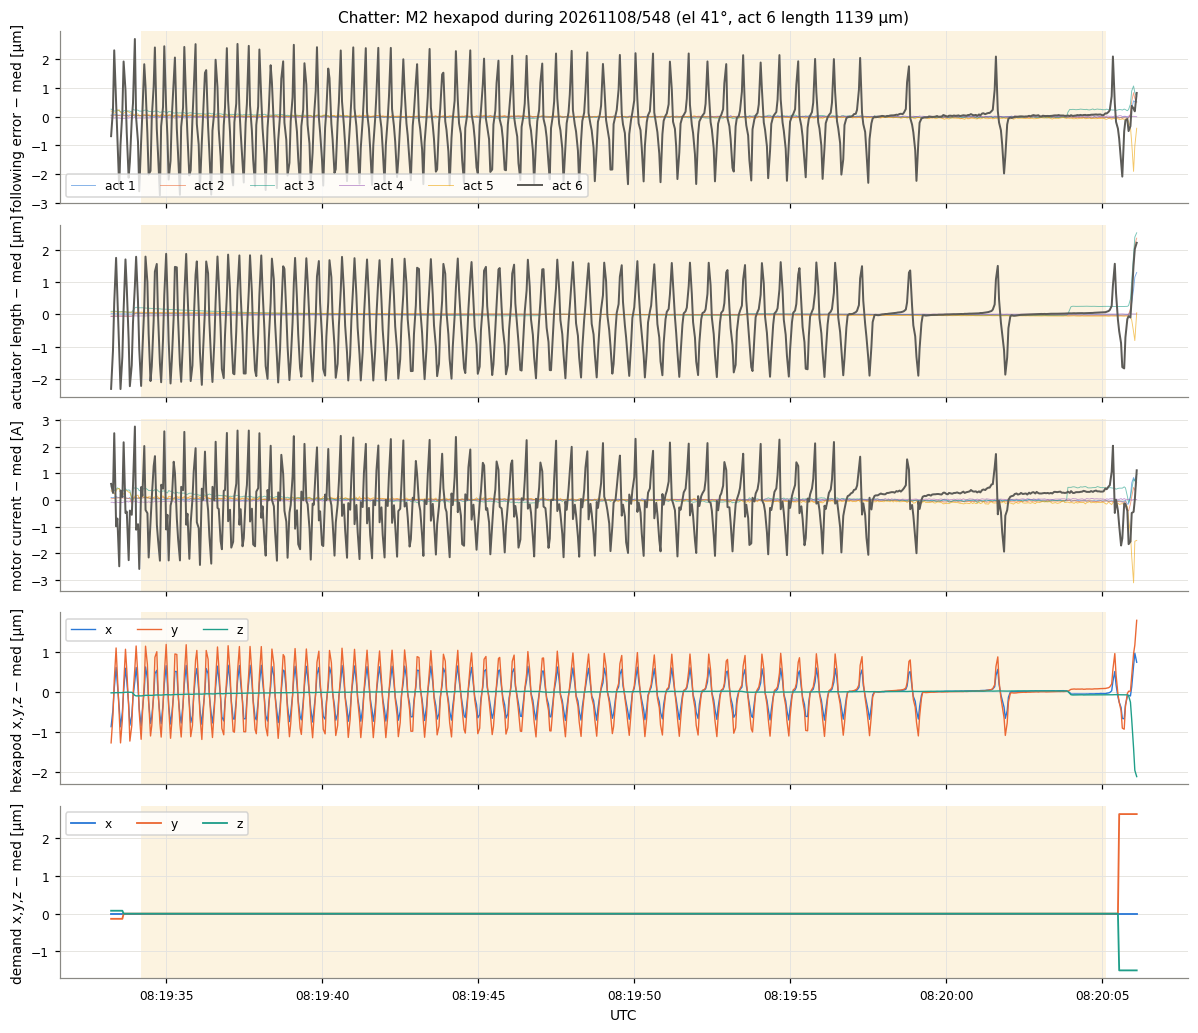

scan metrics act 6: peak 2.69 µm, slip runs 2, chatter fraction 0.89


In [4]:
show_example(EX_CHAT, 6, "Chatter")

Chatter is the same stick-slip repeating as a limit cycle: the actuator sticks, the servo winds up current until it
breaks free, overshoots and sticks again (≈2 Hz here, slowing towards the end). The next exposure (549), at the same
pointing, was quiet — the mode is intermittent.

## 2. Detection thresholds

Per-exposure peak deviation (left pair) and chatter fraction (right pair) for every actuator. The bulk is the servo noise
floor (peak ≈0.05–0.15 µm, chatter fraction 0); slips and chatter form separate tails. `THR` = 0.8 µm and `CHAT` = 0.3
sit well above the noise of every actuator.

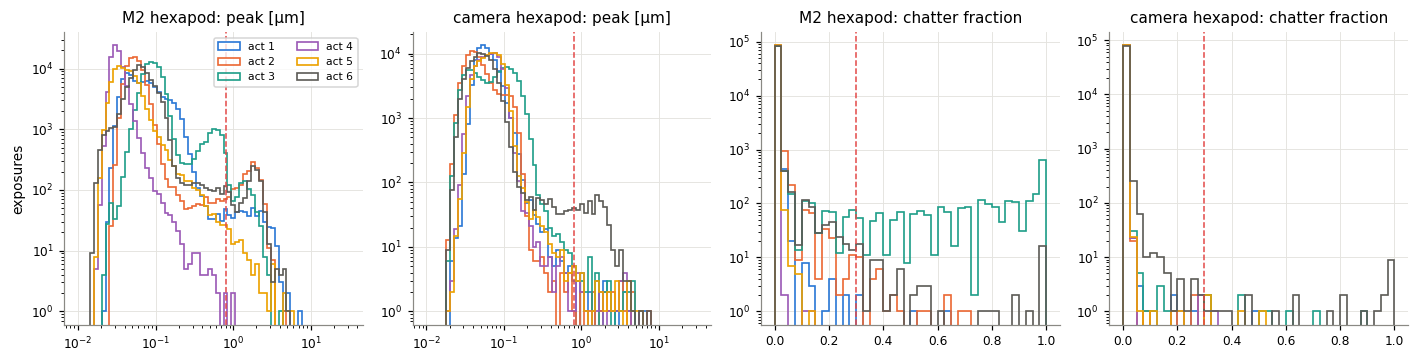

peak median   p90   p99  p99.9
M2 hexapod     act 1         0.07  0.17  0.34   2.52
               act 2         0.05  0.08  1.61   2.40
               act 3         0.09  0.17  0.83   1.90
               act 4         0.03  0.04  0.07   0.19
               act 5         0.04  0.07  0.24   0.94
               act 6         0.06  0.11  1.43   2.39
camera hexapod act 1         0.06  0.09  0.14   0.33
               act 2         0.04  0.10  0.15   0.19
               act 3         0.07  0.15  0.21   0.48
               act 4         0.06  0.10  0.13   0.24
               act 5         0.07  0.10  0.13   0.36
               act 6         0.05  0.08  0.29   1.99

In [5]:
fig, ax = plt.subplots(1, 4, figsize=(13, 3.4))
bins = np.logspace(-2, 1.5, 70); fb = np.linspace(0, 1, 41)
for k, nm in enumerate(HEXES):
    ok = X[X[f"{nm}_ok"]]
    for i in ACTS:
        ax[k].hist(ok[f"{nm}_a{i}_peak"].clip(upper=30), bins=bins, histtype="step", lw=1.1, color=C6[i - 1], label=f"act {i}")
        ax[2 + k].hist(ok[f"{nm}_a{i}_fp2p1"], bins=fb, histtype="step", lw=1.1, color=C6[i - 1])
    ax[k].axvline(THR, color=C_FAULT, ls="--", lw=1); ax[k].set_xscale("log"); ax[k].set_yscale("log")
    ax[k].set_title(f"{HEXES[nm]}: peak [µm]")
    ax[2 + k].axvline(CHAT, color=C_FAULT, ls="--", lw=1); ax[2 + k].set_yscale("log"); ax[2 + k].set_title(f"{HEXES[nm]}: chatter fraction")
ax[0].set_ylabel("exposures"); ax[0].legend(ncol=2, fontsize=7)
plt.tight_layout(); plt.show()
q = pd.DataFrame({(HEXES[nm], f"act {i}"): X.loc[X[f"{nm}_ok"], f"{nm}_a{i}_peak"].quantile([0.5, 0.9, 0.99, 0.999])
                  for nm in HEXES for i in ACTS}).T
q.columns = ["peak median", "p90", "p99", "p99.9"]
display(q.round(2))

### Exposures excluded as commanded / unfinished hexapod motion

From 2025-06 to 2025-12 the hexapod demand was updated *during* most exposures (camera hexapod ≈ 100 %), so those
months contribute little; from 2026-01 almost none are. Separately, a few exposures began while a hexapod was still
travelling to its target (excursions of 10–2000 µm with a constant in-window demand).

In [6]:
m = X.assign(month=X.date.dt.to_period("M"))
agg = {f"{HEXES[nm]} demand moved [%]": (f"{nm}_demand_moved", lambda s: 100 * s.fillna(False).astype(bool).mean()) for nm in HEXES}
for nm in HEXES:
    m[f"{nm}_travel"] = m[f"{nm}_moving"] & (m[f"{nm}_demand_moved"] == False) & (m[f"{nm}_nbins"] >= 5)  # noqa: E712
    X[f"{nm}_travel"] = m[f"{nm}_travel"]
agg.update({f"{HEXES[nm]} still travelling [n]": (f"{nm}_travel", "sum") for nm in HEXES})
display(m.groupby("month").agg(exposures=("exposure_id", "size"), **agg).round(1).T)
mv = X[X.m2_travel | X.cam_travel]
print(f"exposures with a hexapod still travelling: {len(mv)}; largest:")
display(mv.assign(m2_xyz=mv[[f"m2_pos_{c}_peak" for c in "xyz"]].max(axis=1), cam_xyz=mv[[f"cam_pos_{c}_peak" for c in "xyz"]].max(axis=1))
          .nlargest(10, ["cam_xyz"])[["day_obs", "seq_num", "m2_xyz", "cam_xyz", "psf_fwhm", "psf_e"]].round(1))

month,2025-04,2025-05,2025-06,2025-07,2025-08,2025-09,2025-10,2025-11,2025-12,2026-01,2026-02,2026-03,2026-04,2026-05,2026-06,2026-07,2026-10,2026-11
exposures,1682.0,3623.0,3111.0,12044.0,1981.0,1220.0,360.0,4752.0,2645.0,6811.0,5602.0,12652.0,15204.0,11997.0,9909.0,5692.0,1884.0,2544.0
M2 hexapod demand moved [%],1.0,3.0,40.8,86.9,59.5,79.6,49.4,73.7,27.3,0.1,0.0,0.1,1.8,0.1,0.1,0.0,0.1,0.0
camera hexapod demand moved [%],5.0,5.8,55.5,99.8,99.7,99.1,99.7,100.0,38.1,0.0,0.0,0.1,1.8,0.0,0.1,0.0,0.1,0.0
M2 hexapod still travelling [n],1.0,0.0,0.0,4.0,0.0,0.0,0.0,0.0,0.0,4.0,0.0,2.0,12.0,3.0,0.0,0.0,0.0,0.0
camera hexapod still travelling [n],6.0,9.0,14.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,18.0,4.0,0.0,0.0,0.0,0.0


exposures with a hexapod still travelling: 65; largest:


,day_obs,seq_num,m2_xyz,cam_xyz,psf_fwhm,psf_e
6026,20250608,309,1043.2,4582.7,NaN,NaN
15747,20250716,180,912.3,2796.5,1.8,0.6
32027,20260102,138,841.1,2478.9,NaN,NaN
211,20250420,291,914.5,1170.7,NaN,NaN
5941,20250604,416,500.5,923.7,1.8,0.0
75788,20260518,135,744.9,240.8,1.1,0.0
537,20250423,158,0.0,237.5,NaN,NaN
78862,20260524,143,0.1,203.8,2.1,0.6
8029,20250629,348,43.8,82.1,1.6,0.1
228,20250420,308,1.0,67.0,NaN,NaN


## 3. Rates

*Slip* rate is per hour of analysed exposure time (separate runs of bins > `THR`, excluding chatter exposures);
*chatter* is given as the fraction of exposures and of exposure time spent chattering.

In [7]:
rows = []
for nm in HEXES:
    ok = X[X[f"{nm}_ok"]]
    hours = ok.dur_h.sum()
    for i in ACTS:
        sl, ch = ok[f"{nm}_a{i}_slip"], ok[f"{nm}_a{i}_chat"]
        n = ok.loc[sl, f"{nm}_a{i}_n0p8"].sum()
        rows.append({"hexapod": HEXES[nm], "actuator": i,
                     "slip events": int(n), "slips / exp-hour": n / hours,
                     "exposures with slip [%]": sl.mean() * 100, "slip nights": ok.loc[sl, "day_obs"].nunique(),
                     "exposures chattering [%]": ch.mean() * 100,
                     "chatter time [% of exp time]": (ok[f"{nm}_a{i}_fp2p1"] * ok.dur_h)[ch].sum() / hours * 100,
                     "chatter nights": ok.loc[ch, "day_obs"].nunique(),
                     "events > 1.5 µm": int(ok[f"{nm}_a{i}_n1p5"].sum())})
R = pd.DataFrame(rows).set_index(["hexapod", "actuator"])
print("analysed exposure time: " + ", ".join(f"{HEXES[nm]} {X.loc[X[f'{nm}_ok'], 'dur_h'].sum():,.0f} h" for nm in HEXES))
display(R.round(3))

analysed exposure time: M2 hexapod 670 h, camera hexapod 631 h


slip events  slips / exp-hour  exposures with slip [%]  slip nights  exposures chattering [%]  chatter time [% of exp time]  chatter nights  events > 1.5 µm
hexapod        actuator                                                                                                                                                              
M2 hexapod     1                 518             0.773                    0.581          136                     0.005                         0.002               3              298
               2                2002             2.989                    1.810          179                     0.035                         0.015              16             1440
               3                1213             1.811                    0.800           93                     2.791                         2.139              86              485
               4                   3             0.004                    0.002            2                     0.000                         0.000               0                0
               5                 124             0.185                    0.146           66                     0.000                         0.000               0               34
               6                1617             2.414                    1.328          141                     0.091                         0.042              30             1315
camera hexapod 1                  22             0.035                    0.026           13                     0.004                         0.001               3               17
               2                  21             0.033                    0.025           11                     0.000                         0.000               0               15
               3                  33             0.052                    0.039           19                     0.011                         0.006               8               22
               4                  25             0.040                    0.029           12                     0.001                         0.000               1               15
               5                  27             0.043                    0.034           14                     0.005                         0.002               3               20
               6                 476             0.754                    0.536          127                     0.031                         0.024              15              244

### Single-actuator slips versus common-mode disturbances

A genuine actuator stick-slip moves one actuator; an external disturbance (e.g. a mount kick such as the azimuth
encoder-head loss in 20261107/69) shows up on several actuators — and on both hexapods — in the same second. Every
1-s bin with an actuator deviation > `THR` is classified by what else was above `THR` in that second:
**single** (only that actuator), **multi** (other actuators of the same hexapod) or **both hexapods**.

In [8]:
evs = pd.read_parquet(DATA / "hexslip_events.parquet")
okids = {nm: set(X.loc[X[f"{nm}_ok"], "exposure_id"]) for nm in HEXES}
E = evs[evs.dev > THR].copy()
E = E[[eid in okids[h] for eid, h in zip(E.exposure_id, E.hexapod)]]
n_same = E.groupby(["exposure_id", "t", "hexapod"]).actuator.transform("nunique")
other = E.groupby(["exposure_id", "t"]).hexapod.transform("nunique")
E["class"] = np.select([other > 1, n_same > 1], ["both hexapods", "multi"], "single")
tab = E.pivot_table(index=["hexapod", "actuator"], columns="class", values="dev", aggfunc="size", fill_value=0)
tab.index = tab.index.set_levels([HEXES[h] for h in tab.index.levels[0]], level=0)
tab["single fraction"] = tab.get("single", 0) / tab.sum(axis=1)
print("1-s bins with deviation > THR inside usable exposures, by coincidence class:")
display(tab.round(2))

1-s bins with deviation > THR inside usable exposures, by coincidence class:


class                    both hexapods  multi  single  single fraction
hexapod        actuator                                               
camera hexapod 1                    37     10       2             0.04
               2                    24      5       0             0.00
               3                    57     26      34             0.29
               4                    35     13       2             0.04
               5                    36     16       8             0.13
               6                    32     21     612             0.92
M2 hexapod     1                    35    143     700             0.80
               2                    17    127    2860             0.95
               3                    34    168    3893             0.95
               4                     3      0       0             0.00
               5                    10     63     168             0.70
               6                    35     88    3490             0.97

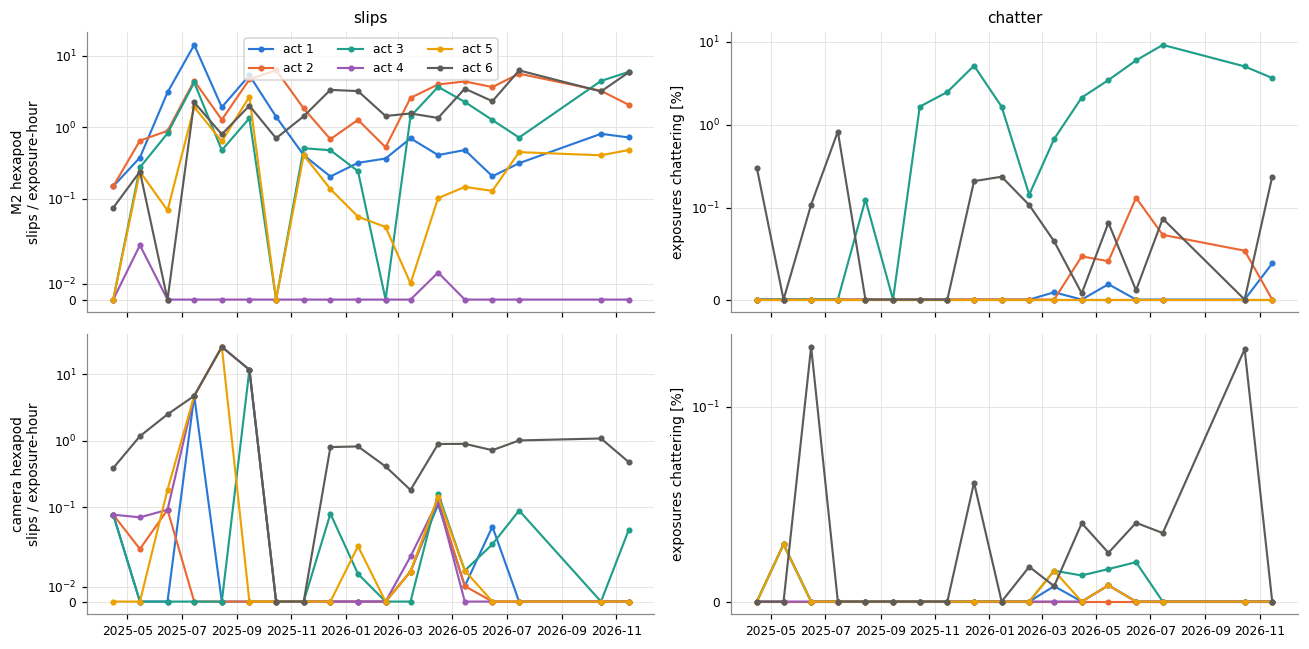

In [9]:
fig, ax = plt.subplots(2, 2, figsize=(12, 6), sharex=True)
for r_, nm in enumerate(HEXES):
    ok = X[X[f"{nm}_ok"]].copy()
    ok["m"] = ok.date.dt.to_period("M").dt.to_timestamp()
    g = ok.groupby("m"); hrs = g.dur_h.sum()
    for i in ACTS:
        sl = ok[f"{nm}_a{i}_n0p8"].where(ok[f"{nm}_a{i}_slip"], 0)
        ax[r_, 0].plot(hrs.index + pd.Timedelta("14D"), sl.groupby(ok.m).sum() / hrs, "o-", ms=3, color=C6[i - 1], label=f"act {i}")
        ax[r_, 1].plot(hrs.index + pd.Timedelta("14D"), ok[f"{nm}_a{i}_chat"].groupby(ok.m).mean() * 100, "o-", ms=3, color=C6[i - 1])
    ax[r_, 0].set_ylabel(f"{HEXES[nm]}\nslips / exposure-hour"); ax[r_, 1].set_ylabel("exposures chattering [%]")
    ax[r_, 0].set_yscale("symlog", linthresh=0.05); ax[r_, 1].set_yscale("symlog", linthresh=0.1)
ax[0, 0].legend(ncol=3); ax[0, 0].set_title("slips"); ax[0, 1].set_title("chatter")
for a in ax[-1]:
    a.xaxis.set_major_formatter(mdates.DateFormatter("%Y-%m"))
plt.tight_layout(); plt.show()

In [10]:
# Nights with the most slip events / chatter on the most active actuators
def worst(nm, col):
    return R.loc[HEXES[nm]][col].idxmax()
for nm in HEXES:
    ok = X[X[f"{nm}_ok"]]
    a_s, a_c = worst(nm, "slip events"), worst(nm, "exposures chattering [%]")
    g = ok.groupby("day_obs").agg(exposures=("exposure_id", "size"),
                                  **{f"act{a_s} slips": (f"{nm}_a{a_s}_n0p8", "sum"),
                                     f"act{a_c} chatter exp": (f"{nm}_a{a_c}_chat", "sum")},
                                  elev_med=("altitude", "median"), air_temp=("air_temp", "median"))
    print(f"{HEXES[nm]}: most slips on act {a_s}, most chatter on act {a_c}")
    display(g.sort_values([f"act{a_s} slips"], ascending=False).head(8).round(1))
    display(g.sort_values([f"act{a_c} chatter exp"], ascending=False).head(8).round(1))

M2 hexapod: most slips on act 2, most chatter on act 3


,exposures,act2 slips,act3 chatter exp,elev_med,air_temp
day_obs,,,,,
20260626,906,116.0,6,59.6,8.1
20260526,830,75.0,41,60.6,11.3
20260708,559,70.0,0,65.2,10.5
20260405,769,51.0,0,56.6,9.2
20260705,834,45.0,173,58.7,7.0
20260530,814,45.0,40,59.1,11.6
20260329,788,39.0,3,64.3,16.4
20260709,729,39.0,19,62.2,10.6


,exposures,act2 slips,act3 chatter exp,elev_med,air_temp
day_obs,,,,,
20260705,834,45.0,173,58.7,7.0
20260711,822,25.0,160,51.8,12.3
20260706,899,21.0,139,61.1,9.9
20260630,700,6.0,134,54.3,4.1
20261030,579,9.0,85,57.7,7.9
20260629,875,13.0,85,53.4,6.9
20260606,699,16.0,82,61.3,5.6
20260607,840,28.0,80,60.7,7.4


camera hexapod: most slips on act 6, most chatter on act 6


,exposures,act6 slips,act6 chatter exp,elev_med,air_temp
day_obs,,,,,
20260705,834,19,1,58.7,7.0
20260630,700,15,0,54.3,4.1
20260706,899,11,0,61.1,9.9
20260523,625,11,0,61.9,6.1
20260430,640,10,0,57.9,9.1
20260627,866,10,2,59.1,8.0
20260421,727,10,0,61.8,7.3
20260429,809,10,0,60.5,12.4


,exposures,act6 slips,act6 chatter exp,elev_med,air_temp
day_obs,,,,,
20260412,737,1,4,66.5,11.2
20261030,579,8,2,57.7,7.9
20261029,624,4,2,63.9,8.0
20260406,632,4,2,52.0,10.3
20250607,5,2,2,46.2,5.2
20260628,807,2,2,56.5,9.9
20260526,830,7,2,60.6,11.3
20260627,866,10,2,59.1,8.0


## 4. What drives it

Occurrence on the most active actuators versus telescope elevation and outside air temperature, with Poisson 1σ errors. Stick-slip in a ball-screw / flexure actuator is expected where the axial
load is near zero (friction and backlash dominate) — for the M2 hexapod that is set by elevation (gravity) and by where
the compensation table has put the actuator.

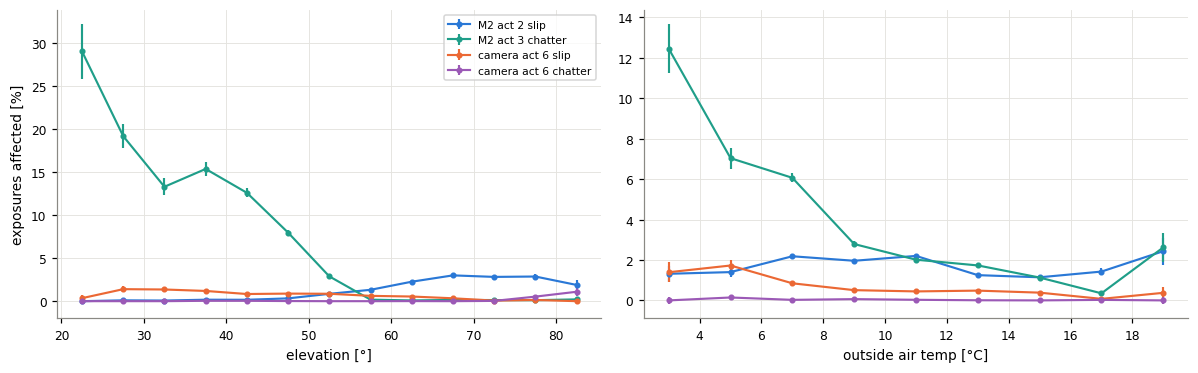

In [11]:
def occ(ok, col, flag, bins):
    c = pd.cut(ok[col], bins)
    g = ok.groupby(c, observed=True)
    n, N = g[flag].sum(), g[flag].size()
    return pd.DataFrame({"n": n, "N": N, "pct": 100 * n / N, "err": 100 * np.sqrt(np.maximum(n, 1)) / N})

targets = []
for nm in HEXES:
    targets.append((nm, R.loc[HEXES[nm]]["slip events"].idxmax(), "slip"))
    targets.append((nm, R.loc[HEXES[nm]]["exposures chattering [%]"].idxmax(), "chat"))
fig, ax = plt.subplots(1, 2, figsize=(11, 3.5))
for (nm, act, kind), colr in zip(targets, [C_M2, "#1f9e89", C_CAM, "#9b59b6"]):
    ok = X[X[f"{nm}_ok"]]
    for a, (col_, bins, lab) in zip(ax, [("altitude", np.arange(20, 91, 5), "elevation [°]"),
                                         ("air_temp", np.arange(-6, 24, 2), "outside air temp [°C]")]):
        r = occ(ok, col_, f"{nm}_a{act}_{kind}", bins); r = r[r.N >= 30]
        a.errorbar([iv.mid for iv in r.index], r.pct, r.err, fmt="o-", ms=3, color=colr,
                   label=f"{HEXES[nm].split()[0]} act {act} {'chatter' if kind == 'chat' else 'slip'}")
        a.set_xlabel(lab)
ax[0].set_ylabel("exposures affected [%]"); ax[0].legend(fontsize=7)
plt.tight_layout(); plt.show()

Elevation and temperature are correlated through the season, so the chatter fraction of the most-chattering actuator is
split in 2-D below, and its month-by-month evolution is shown at low elevation only (el < 45°), where it occurs — this
separates a real change in the actuator from a change in where the telescope pointed.

M2 hexapod actuator 3: exposures chattering [%] (number of exposures)


air temp [°C],"(-10, 5]","(5, 9]","(9, 13]","(13, 30]"
elevation,,,,
"(15, 35]",35.9 (92),21.1 (620),15.4 (1364),14.5 (601)
"(35, 45]",51.2 (207),23.5 (1589),11.3 (4066),2.7 (1372)
"(45, 55]",18.0 (328),11.0 (3767),3.8 (9298),0.8 (3248)
"(55, 65]",0.3 (625),0.3 (6191),0.1 (12841),0.0 (4891)
"(65, 90]",1.0 (483),0.3 (7577),0.1 (18095),0.0 (7654)


M2 hexapod actuator 3 chatter at elevation < 45°, by month:


date,2025-04,2025-05,2025-06,2025-07,2025-08,2025-09,2025-10,2025-11,2025-12,2026-01,2026-02,2026-03,2026-04,2026-05,2026-06,2026-07,2026-10,2026-11
exposures,162.0,599.0,217.0,130.0,22.0,14.0,12.0,134.0,450.0,1050.0,931.0,1006.0,1315.0,1156.0,1298.0,900.0,258.0,257.0
chatter_pct,0.0,0.0,0.0,0.0,4.5,0.0,0.0,6.0,12.9,10.0,0.3,1.7,13.0,24.3,26.3,32.4,32.2,29.6
median_air_temp,9.5,11.4,9.4,11.0,9.7,5.6,10.2,9.0,12.5,13.8,12.6,12.6,10.4,10.2,8.2,11.8,7.7,10.8
median_elev,42.5,42.1,39.5,39.4,39.8,34.5,42.4,42.6,34.9,37.9,40.8,39.0,40.1,40.2,39.5,40.1,35.5,40.2


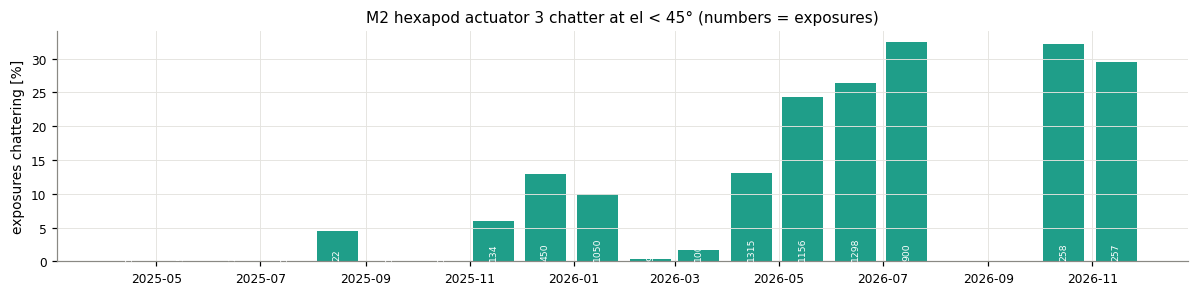

In [12]:
nm, act = "m2", R.loc[HEXES["m2"]]["exposures chattering [%]"].idxmax()
ok = X[X[f"{nm}_ok"]].copy()
flag = f"{nm}_a{act}_chat"
ok["elevation"] = pd.cut(ok.altitude, [15, 35, 45, 55, 65, 90])
ok["air temp [°C]"] = pd.cut(ok.air_temp, [-10, 5, 9, 13, 30])
t = ok.pivot_table(index="elevation", columns="air temp [°C]", values=flag, aggfunc=["mean", "size"], observed=True)
print(f"{HEXES[nm]} actuator {act}: exposures chattering [%] (number of exposures)")
display((t["mean"] * 100).round(1).astype(str) + " (" + t["size"].astype(str) + ")")
lo = ok[ok.altitude < 45]
trend = lo.groupby(lo.date.dt.to_period("M")).agg(exposures=(flag, "size"), chatter_pct=(flag, lambda s: 100 * s.mean()),
                                                  median_air_temp=("air_temp", "median"), median_elev=("altitude", "median"))
print(f"{HEXES[nm]} actuator {act} chatter at elevation < 45°, by month:")
display(trend.round(1).T)
fig, a = plt.subplots(figsize=(11, 2.8))
a.bar(trend.index.to_timestamp() + pd.Timedelta("14D"), trend.chatter_pct, width=24, color="#1f9e89")
for x_, n_ in zip(trend.index.to_timestamp(), trend.exposures):
    a.text(x_ + pd.Timedelta("14D"), 0.5, f"{n_}", ha="center", fontsize=6, color="white" if n_ > 0 else C_GRAY, rotation=90)
a.set_ylabel("exposures chattering [%]"); a.set_title(f"{HEXES[nm]} actuator {act} chatter at el < 45° (numbers = exposures)")
a.xaxis.set_major_formatter(mdates.DateFormatter("%Y-%m")); plt.tight_layout(); plt.show()

## 5. Effect on the hexapod position

Peak deviation of the hexapod's own position solution (x, y, z in µm; u, v in arcsec) during exposures, by class.

In [13]:
rows = []
for nm in HEXES:
    ok = X[X[f"{nm}_ok"]].copy()
    ok["cls"] = np.select([ok[f"{nm}_any_chat"], ok[f"{nm}_any_slip"]], ["chatter", "slip"], "clean")
    for cls, g in ok.groupby("cls"):
        d = {"hexapod": HEXES[nm], "class": cls, "exposures": len(g)}
        for lab in "xyzuv":
            unit = "µm" if lab in "xyz" else "″"
            d[f"{lab} med [{unit}]"] = g[f"{nm}_pos_{lab}_peak"].median()
            d[f"{lab} p95 [{unit}]"] = g[f"{nm}_pos_{lab}_peak"].quantile(0.95)
        rows.append(d)
display(pd.DataFrame(rows).set_index(["hexapod", "class"]).round(3))

exposures  x med [µm]  x p95 [µm]  y med [µm]  y p95 [µm]  z med [µm]  z p95 [µm]  u med [″]  u p95 [″]  v med [″]  v p95 [″]
hexapod        class                                                                                                                                 
M2 hexapod     chatter       2472       0.024       0.555       0.037       0.860       0.035       0.174      0.004      0.025      0.004      0.018
               clean        78958       0.015       0.055       0.039       0.103       0.023       0.053      0.003      0.008      0.002      0.006
               slip          3479       0.421       0.661       0.353       1.089       0.429       1.117      0.052      0.160      0.064      0.122
camera hexapod chatter         33       0.211       3.706       0.287       2.281       0.024       0.506      0.013      0.130      0.017      0.314
               clean        79529       0.079       0.238       0.145       0.296       0.009       0.021      0.008      0.017      0.006      0.018
               slip           457       1.788       2.980       0.801       1.603       0.258       0.851      0.010      0.132      0.155      0.318

## 6. Effect on the images

Each affected exposure is compared with the median of its ±2 neighbouring exposures on the same night that were clean on
that hexapod (same cadence, similar seeing). Paired differences (affected − neighbours) of PSF FWHM, PSF ellipticity,
guider detrended rms (az, alt) and guider FWHM scatter: median with bootstrap 68 % interval. The control row repeats the
comparison for randomly drawn clean exposures (expected ≈0).

In [14]:
METRICS = {"psf_fwhm": "PSF FWHM [″]", "psf_e": "PSF e", "guider_azimuth_rms_detrended": "guider az rms [″]",
           "guider_altitude_rms_detrended": "guider alt rms [″]", "guider_psf_fwhm_standard_deviation": "guider FWHM σ [″]"}
rng = np.random.default_rng(1)

def paired(nm, idx, ok):
    clean = ~(ok[f"{nm}_any_chat"] | ok[f"{nm}_any_slip"])
    cl = ok[clean].set_index(["day_obs", "seq_num"])
    clix = set(cl.index)
    out = []
    for _, r in ok.loc[idx].iterrows():
        nb = [(r.day_obs, r.seq_num + d) for d in (-2, -1, 1, 2) if (r.day_obs, r.seq_num + d) in clix]
        if len(nb) >= 2:
            out.append({m: r[m] - cl.loc[nb, m].median() for m in METRICS})
    return pd.DataFrame(out, columns=list(METRICS))

def boot(s):
    s = s.dropna().to_numpy()
    if len(s) < 5:
        return np.nan, np.nan, np.nan, len(s)
    b = [np.median(rng.choice(s, len(s))) for _ in range(1000)]
    return np.median(s), np.percentile(b, 16), np.percentile(b, 84), len(s)

rows = []
for nm in HEXES:
    ok = X[X[f"{nm}_ok"]].reset_index(drop=True)
    clean = ~(ok[f"{nm}_any_chat"] | ok[f"{nm}_any_slip"])
    groups = {f"slip, peak < 2 µm": ok.index[ok[f"{nm}_any_slip"] & ~ok[f"{nm}_any_chat"] & (ok[f"{nm}_maxpk"] < 2)],
              f"slip, peak ≥ 2 µm": ok.index[ok[f"{nm}_any_slip"] & ~ok[f"{nm}_any_chat"] & (ok[f"{nm}_maxpk"] >= 2)],
              "chatter": ok.index[ok[f"{nm}_any_chat"]],
              "control (clean)": pd.Index(rng.choice(ok.index[clean], size=min(3000, int(clean.sum())), replace=False))}
    for gname, idx in groups.items():
        P = paired(nm, idx, ok)
        for m, lab in METRICS.items():
            med, lo, hi, n = boot(P[m])
            rows.append(dict(hexapod=HEXES[nm], group=gname, metric=lab, n=n, median_diff=med, lo68=lo, hi68=hi))
IMG = pd.DataFrame(rows)
print("median paired difference (affected − clean neighbours):")
display(IMG.pivot_table(index=["hexapod", "group"], columns="metric", values="median_diff", sort=False).round(3))
print("bootstrap 68 % interval (lo, hi):")
display((IMG.assign(ci=IMG.apply(lambda r: f"{r.lo68:+.3f} … {r.hi68:+.3f}", axis=1))
         .pivot_table(index=["hexapod", "group"], columns="metric", values="ci", aggfunc="first", sort=False)))
print("number of pairs:")
display(IMG.pivot_table(index=["hexapod", "group"], columns="metric", values="n", sort=False))

median paired difference (affected − clean neighbours):


metric                            PSF FWHM [″]  PSF e  guider az rms [″]  guider alt rms [″]  guider FWHM σ [″]
hexapod        group                                                                                           
M2 hexapod     slip, peak < 2 µm         0.001 -0.000              0.000               0.001             -0.000
               slip, peak ≥ 2 µm         0.005  0.002              0.000               0.000             -0.004
               chatter                   0.007 -0.001              0.001               0.002              0.002
               control (clean)          -0.000 -0.000             -0.001              -0.000             -0.000
camera hexapod slip, peak < 2 µm         0.007 -0.003              0.000               0.001             -0.002
               slip, peak ≥ 2 µm         0.006  0.002              0.002               0.004             -0.005
               chatter                   0.027 -0.011              0.000              -0.002              0.009
               control (clean)          -0.001 -0.000             -0.000               0.000             -0.000

bootstrap 68 % interval (lo, hi):


metric                               PSF FWHM [″]            PSF e guider az rms [″] guider alt rms [″] guider FWHM σ [″]
hexapod        group                                                                                                     
M2 hexapod     slip, peak < 2 µm  +0.000 … +0.003  -0.001 … +0.000   -0.000 … +0.001    +0.001 … +0.001   -0.001 … +0.001
               slip, peak ≥ 2 µm  +0.003 … +0.008  -0.001 … +0.003   -0.000 … +0.001    -0.001 … +0.001   -0.005 … -0.002
               chatter            +0.004 … +0.009  -0.002 … -0.001   +0.000 … +0.001    +0.001 … +0.002   +0.000 … +0.004
               control (clean)    -0.001 … +0.001  -0.001 … +0.000   -0.001 … -0.001    -0.000 … +0.000   -0.001 … +0.000
camera hexapod slip, peak < 2 µm  +0.003 … +0.009  -0.004 … -0.001   -0.001 … +0.001    -0.000 … +0.003   -0.005 … +0.000
               slip, peak ≥ 2 µm  -0.003 … +0.015  -0.001 … +0.009   -0.001 … +0.003    +0.001 … +0.008   -0.016 … -0.000
               chatter            -0.018 … +0.045  -0.016 … +0.009   -0.004 … +0.003    -0.005 … +0.006   -0.001 … +0.023
               control (clean)    -0.002 … +0.000  -0.001 … +0.000   -0.000 … +0.000    -0.000 … +0.000   -0.001 … -0.000

number of pairs:


metric                            PSF FWHM [″]   PSF e  guider az rms [″]  guider alt rms [″]  guider FWHM σ [″]
hexapod        group                                                                                            
M2 hexapod     slip, peak < 2 µm        2239.0  2239.0             1556.0              1556.0             1556.0
               slip, peak ≥ 2 µm         677.0   677.0              513.0               513.0              513.0
               chatter                  1072.0  1072.0              791.0               791.0              791.0
               control (clean)          2814.0  2814.0             1850.0              1850.0             1850.0
camera hexapod slip, peak < 2 µm         342.0   342.0              191.0               191.0              191.0
               slip, peak ≥ 2 µm          84.0    84.0               51.0                51.0               51.0
               chatter                    28.0    28.0               18.0                18.0               18.0
               control (clean)          2878.0  2878.0             1981.0              1981.0             1981.0

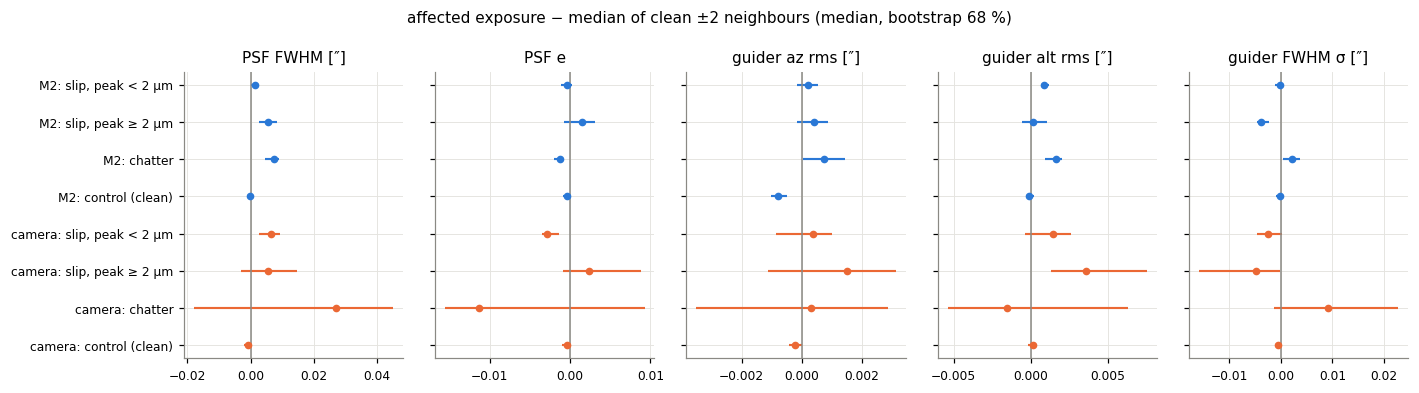

In [15]:
fig, ax = plt.subplots(1, len(METRICS), figsize=(13, 3.6), sharey=True)
lab_rows = IMG[IMG.metric == list(METRICS.values())[0]][["hexapod", "group"]].reset_index(drop=True)
for a, lab in zip(ax, METRICS.values()):
    s = IMG[IMG.metric == lab].reset_index(drop=True)
    for k, r in s.iterrows():
        c = C_M2 if r.hexapod == "M2 hexapod" else C_CAM
        a.errorbar(r.median_diff, k, xerr=[[r.median_diff - r.lo68], [r.hi68 - r.median_diff]], fmt="o", ms=4, color=c, ecolor=c)
    a.axvline(0, color=C_GRAY, lw=1); a.set_title(lab)
ax[0].set_yticks(range(len(lab_rows)), [f"{h.split()[0]}: {g}" for h, g in zip(lab_rows.hexapod, lab_rows.group)])
ax[0].invert_yaxis()
plt.suptitle("affected exposure − median of clean ±2 neighbours (median, bootstrap 68 %)", fontsize=10)
plt.tight_layout(); plt.show()

In [16]:
# Largest individual cases
for nm in HEXES:
    ok = X[X[f"{nm}_ok"]].copy()
    ok["worst_act"] = ok[[f"{nm}_a{i}_peak" for i in ACTS]].idxmax(axis=1).str.extract(r"_a(\d)_")[0].astype(int)
    ok["chat_frac_max"] = ok[[f"{nm}_a{i}_fp2p1" for i in ACTS]].max(axis=1)
    print(HEXES[nm], "— largest peaks")
    display(ok.nlargest(8, f"{nm}_maxpk")[["day_obs", "seq_num", "altitude", "air_temp", "worst_act", f"{nm}_maxpk",
             "chat_frac_max", f"{nm}_pos_x_peak", f"{nm}_pos_y_peak", f"{nm}_pos_z_peak", "psf_fwhm", "psf_e",
             "guider_azimuth_rms_detrended"]].round(2))

M2 hexapod — largest peaks


,day_obs,seq_num,altitude,air_temp,worst_act,m2_maxpk,chat_frac_max,m2_pos_x_peak,m2_pos_y_peak,m2_pos_z_peak,psf_fwhm,psf_e,guider_azimuth_rms_detrended
102866,20261106,638,63.77,11.30,1,7.17,0.64,0.02,2.24,1.71,1.72,0.10,0.12
20482,20250806,363,42.86,5.55,5,6.12,0.04,1.28,2.49,1.61,1.34,0.06,NaN
101448,20261104,293,44.22,9.06,1,5.30,0.03,0.03,1.67,1.34,1.88,0.03,NaN
11956,20250708,275,43.08,10.48,6,5.22,0.46,0.29,0.50,0.10,2.40,0.06,NaN
87268,20260613,232,68.04,8.25,1,5.12,0.03,0.01,1.68,1.30,1.54,0.20,0.12
21467,20250816,471,42.43,4.88,5,5.02,0.07,1.46,2.54,0.67,1.93,0.03,NaN
20332,20250728,388,42.81,11.12,6,4.85,0.06,1.55,1.62,1.12,1.59,0.06,NaN
15745,20250716,178,81.70,11.05,6,4.65,1.00,0.29,0.46,0.02,1.15,0.12,NaN


camera hexapod — largest peaks


,day_obs,seq_num,altitude,air_temp,worst_act,cam_maxpk,chat_frac_max,cam_pos_x_peak,cam_pos_y_peak,cam_pos_z_peak,psf_fwhm,psf_e,guider_azimuth_rms_detrended
57707,20260404,394,59.87,15.00,2,7.35,0.04,0.65,0.92,7.12,1.04,0.11,0.06
91657,20260628,496,39.21,9.90,6,7.07,0.04,8.54,3.65,1.18,1.12,0.16,0.06
8019,20250629,318,59.29,5.60,2,6.01,0.04,2.39,2.36,0.79,1.95,0.58,NaN
90950,20260627,668,53.43,7.80,6,5.59,0.07,7.08,2.77,0.98,1.11,0.07,0.10
59213,20260406,447,57.79,10.62,5,4.90,0.04,5.54,1.91,4.28,1.04,0.07,0.08
64612,20260415,106,48.26,10.91,3,4.80,0.32,2.43,2.36,0.11,1.44,0.04,NaN
59599,20260407,125,59.13,11.60,5,4.77,0.03,0.53,1.38,1.45,1.37,0.07,0.08
91669,20260628,508,39.66,9.85,6,4.75,0.03,6.01,2.58,0.83,0.96,0.11,0.06


## 7. Conclusions and suggested actions

* **Two modes, one mechanism.** Isolated *slips* (20261107/96) and sustained *chatter* (20261108/548) are both
  stick-slip of single hexapod actuators. In each, the actuator sticks, the drive current winds up until it breaks
  free, it overshoots by ~2 µm, and it either settles (slip) or sticks again (chatter, ≈ 2 Hz). Demand stays constant
  throughout and other actuators are quiet, so this is not commanded motion and not an external disturbance.
* **For the hexapod team.**
  1. **M2 actuator 3 is degrading.** At low elevation its chatter fraction went from 0 % in mid-2025 to ~30 % of
     exposures since May 2026, at similar temperatures. The elevation and cold dependence point at friction under low
     axial preload (lubrication, preload, flexure or brake drag), or at servo tuning that cannot hold the actuator in
     that regime. Inspect it before it grows into something that affects images or trips the hexapod.
     The Feb–Mar 2026 dip is worth matching against maintenance or configuration records.
  2. **M2 actuators 2 and 6 and camera actuator 6** slip a few times per exposure-hour. These are lower priority, but
     they are the same mechanism and worth checking at the same time.
  3. Friction compensation or a small deadband in the actuator loop would probably remove chatter even without
     hardware work. That is for the hexapod team to judge.
* **For operations / data quality.** No action is needed for image quality at present amplitudes: FWHM changes by
  ≤ 0.007″. Separately, exposures that start while a hexapod is still travelling (§2) are worth preventing with a
  stricter in-position check before `startIntegration`.
* **Monitoring metric.** Each night, the fraction of exposures at el < 45° in which M2 actuator 3 chatters. It is 0 %
  when healthy and ~30 % now.
* **Caveats.** Most of 2025-06 → 2025-12 is excluded, because the hexapod demand was updated during exposures then.
  The 1-s scan counts a burst of slips inside one second as one event. The image comparison is against ±2 neighbours
  of the same night, so pointing-dependent effects are partly shared.
* **Reproduce.** `python3 -E build_hexapod_slip.py` (~1.5 h, resumable per night), then `--examples`, then run this
  notebook.